DATASET OVERVIEW
Rows and columns: (12000, 13)


,order_id,order_date,customer_segment,city,category,quantity,unit_price,discount_pct,payment_status,order_month,order_year,gross_sales,net_sales
0,RT-100001,2026-10-13,Student,Pune,Learning Kit,1.0,799.0,10.0,Paid,10,2026,799.0,719.10
1,RT-100002,2026-01-07,Professional,Hyderabad,Learning Kit,3.0,799.0,5.0,Paid,1,2026,2397.0,2277.15
2,RT-100003,2026-01-18,Professional,Delhi,Course Access,2.0,1499.0,15.0,Refunded,1,2026,2998.0,2548.30
3,RT-100004,2026-01-12,Professional,Mumbai,Mentor Session,2.0,999.0,0.0,Paid,1,2026,1998.0,1998.00
4,RT-100005,2026-01-07,Professional,Hyderabad,Learning Kit,3.0,799.0,5.0,Paid,1,2026,2397.0,2277.15



DESCRIPTIVE STATISTICS


,count,mean,std,min,25%,50%,75%,max
quantity,12000.0,1.571417,0.753844,1.0,1.0,1.0,2.0,3.0
unit_price,12000.0,1079.333333,304.364270,799.0,799.0,999.0,1499.0,1499.0
discount_pct,12000.0,3.728333,5.030488,0.0,0.0,0.0,10.0,15.0
order_month,12000.0,1.764250,2.508923,1.0,1.0,1.0,1.0,10.0
order_year,12000.0,2026.000000,0.000000,2026.0,2026.0,2026.0,2026.0,2026.0
gross_sales,12000.0,1607.695250,666.710429,799.0,999.0,1499.0,1998.0,2998.0
net_sales,12000.0,1531.747742,584.088888,719.1,999.0,1499.0,1998.0,2548.3



MEDIAN VALUES


,Median
quantity,1.0
unit_price,999.0
discount_pct,0.0
order_month,1.0
order_year,2026.0
gross_sales,1499.0
net_sales,1499.0


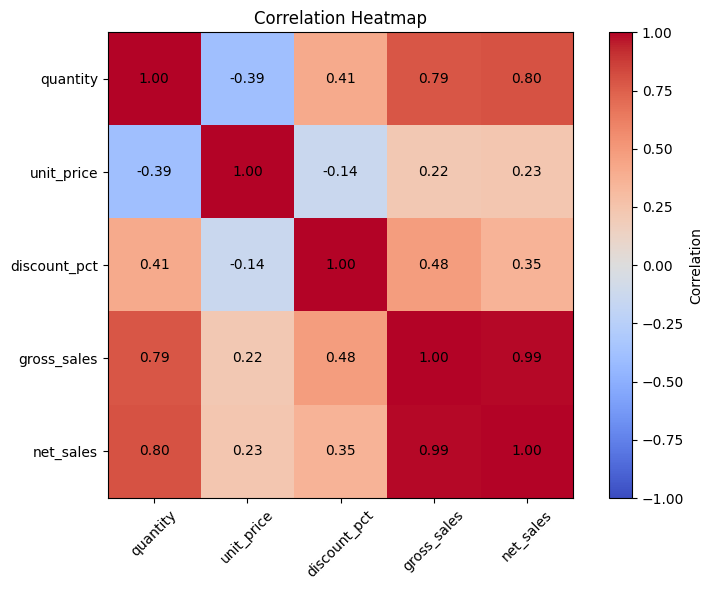

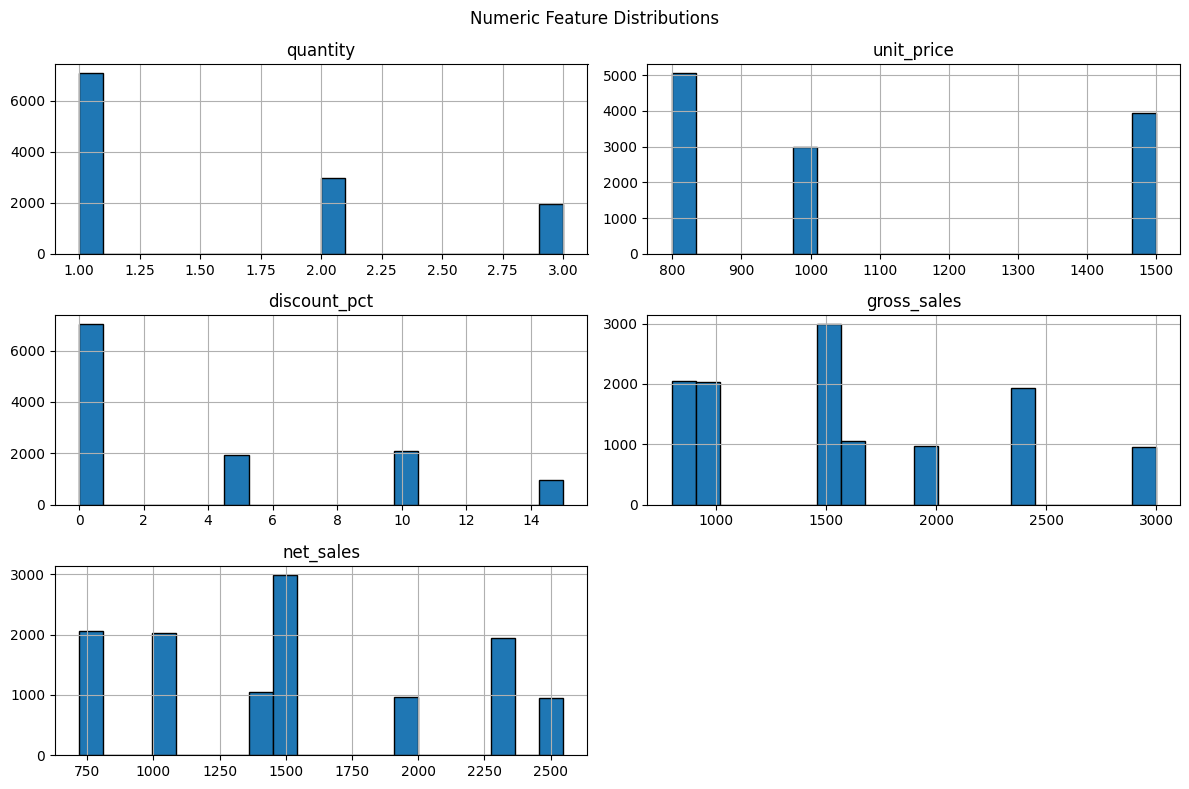

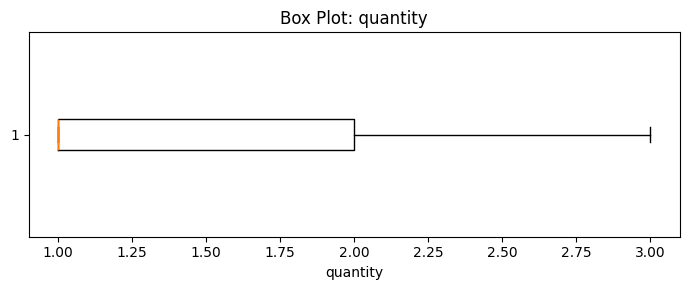

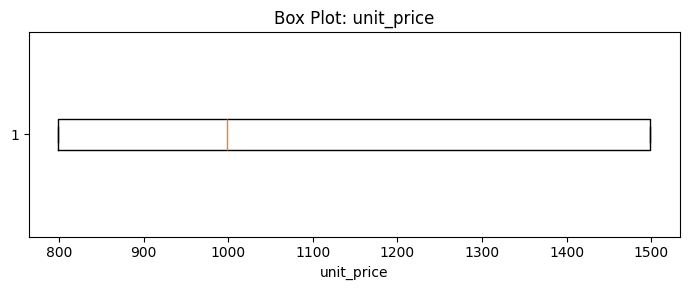

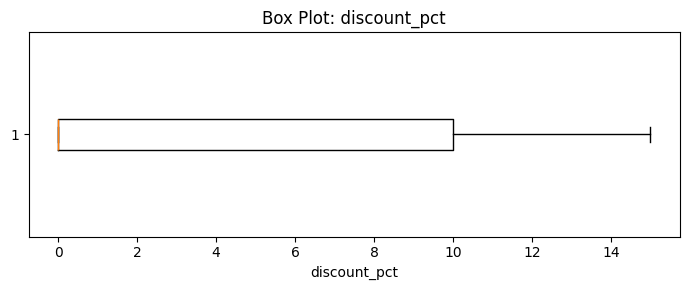

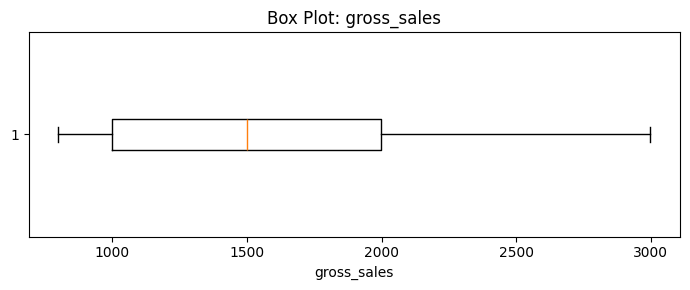

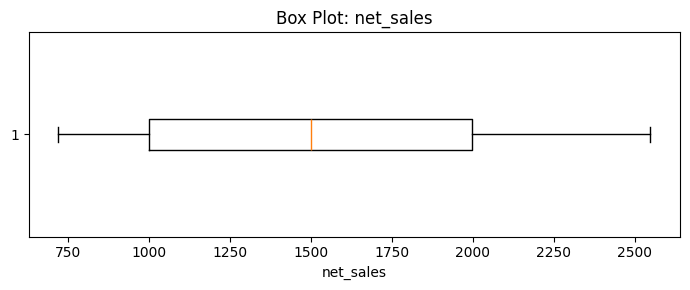

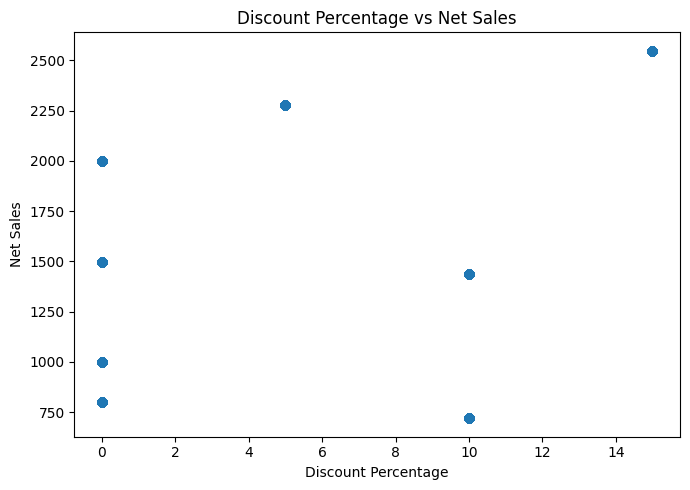


HYPOTHESIS TESTING

H1: Discount percentage is associated with quantity
Spearman correlation = 0.575, p-value = 0.0000
Conclusion: Evidence of an association

H2: Net sales differ across customer segments
Kruskal-Wallis statistic = 8840.364, p-value = 0.0000
Conclusion: Evidence of a difference among at least two segments

H3: Net sales differ between Paid and non-Paid orders
Mann-Whitney U = 12408717.5, p-value = 0.0000
Conclusion: Evidence of a difference in the distributions


## Top 5 Critical Findings

- Average net sales: 1531.75; median net sales: 1499.00.
- Average discount percentage: 3.73.
- Most common payment status: Paid.
- Most common product category: Learning Kit.
- Most common customer segment: Student.

**Data note:** This is synthetic practice data. These findings describe this dataset only and should not be treated as conclusions about a real business.

In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from IPython.display import display, Markdown
from scipy import stats

# 1. Load dataset
df = pd.read_csv("clean_dataset.csv")

print("DATASET OVERVIEW")
print("Rows and columns:", df.shape)
display(df.head())

# 2. Descriptive statistics
numeric_cols = df.select_dtypes(include=np.number).columns.tolist()

print("\nDESCRIPTIVE STATISTICS")
display(df[numeric_cols].describe().T)

print("\nMEDIAN VALUES")
display(df[numeric_cols].median().to_frame("Median"))

# 3. Correlation heatmap
corr_cols = [
    col for col in
    ["quantity", "unit_price", "discount_pct", "gross_sales", "net_sales"]
    if col in df.columns
]

if len(corr_cols) >= 2:
    corr = df[corr_cols].corr(numeric_only=True)

    plt.figure(figsize=(8, 6))
    plt.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
    plt.colorbar(label="Correlation")
    plt.xticks(range(len(corr.columns)), corr.columns, rotation=45)
    plt.yticks(range(len(corr.index)), corr.index)
    plt.title("Correlation Heatmap")
    for i in range(len(corr.columns)):
        for j in range(len(corr.columns)):
            plt.text(j, i, f"{corr.iloc[i, j]:.2f}",
                     ha="center", va="center")
    plt.tight_layout()
    plt.show()

# 4. Histograms
hist_cols = [
    col for col in
    ["quantity", "unit_price", "discount_pct", "gross_sales", "net_sales"]
    if col in df.columns
]

df[hist_cols].hist(figsize=(12, 8), bins=20, edgecolor="black")
plt.suptitle("Numeric Feature Distributions")
plt.tight_layout()
plt.show()

# 5. Box plots to identify possible outliers
for col in hist_cols:
    plt.figure(figsize=(7, 3))
    plt.boxplot(df[col].dropna(), vert=False)
    plt.title(f"Box Plot: {col}")
    plt.xlabel(col)
    plt.tight_layout()
    plt.show()

# 6. Multivariate visualization: discount vs net sales
if {"discount_pct", "net_sales"}.issubset(df.columns):
    plt.figure(figsize=(7, 5))
    plt.scatter(df["discount_pct"], df["net_sales"], alpha=0.4)
    plt.xlabel("Discount Percentage")
    plt.ylabel("Net Sales")
    plt.title("Discount Percentage vs Net Sales")
    plt.tight_layout()
    plt.show()

# 7. Hypothesis tests
print("\nHYPOTHESIS TESTING")
alpha = 0.05
hypothesis_results = []

# Hypothesis 1: Discount percentage is associated with quantity
if {"discount_pct", "quantity"}.issubset(df.columns):
    temp = df[["discount_pct", "quantity"]].dropna()
    r, p = stats.spearmanr(temp["discount_pct"], temp["quantity"])
    hypothesis_results.append((
        "H1: Discount percentage is associated with quantity",
        f"Spearman correlation = {r:.3f}, p-value = {p:.4f}",
        "Evidence of an association" if p < alpha else
        "No statistically significant association detected"
    ))

# Hypothesis 2: Net sales differ by customer segment
if {"customer_segment", "net_sales"}.issubset(df.columns):
    groups = [
        group["net_sales"].dropna().values
        for _, group in df.groupby("customer_segment")
        if len(group["net_sales"].dropna()) > 0
    ]
    segment_names = [
        name for name, group in df.groupby("customer_segment")
        if len(group["net_sales"].dropna()) > 0
    ]

    if len(groups) >= 2:
        h, p = stats.kruskal(*groups)
        hypothesis_results.append((
            "H2: Net sales differ across customer segments",
            f"Kruskal-Wallis statistic = {h:.3f}, p-value = {p:.4f}",
            "Evidence of a difference among at least two segments"
            if p < alpha else
            "No statistically significant difference detected"
        ))

# Hypothesis 3: Net sales differ between Paid and non-Paid orders
if {"payment_status", "net_sales"}.issubset(df.columns):
    status = df["payment_status"].astype(str).str.strip().str.lower()
    paid = df.loc[status == "paid", "net_sales"].dropna()
    non_paid = df.loc[status != "paid", "net_sales"].dropna()

    if len(paid) >= 2 and len(non_paid) >= 2:
        u, p = stats.mannwhitneyu(
            paid, non_paid, alternative="two-sided"
        )
        hypothesis_results.append((
            "H3: Net sales differ between Paid and non-Paid orders",
            f"Mann-Whitney U = {u:.1f}, p-value = {p:.4f}",
            "Evidence of a difference in the distributions"
            if p < alpha else
            "No statistically significant difference detected"
        ))

for title, test_result, conclusion in hypothesis_results:
    print("\n" + title)
    print(test_result)
    print("Conclusion:", conclusion)

# 8. Top five data findings
findings = []

if "net_sales" in df.columns:
    findings.append(
        f"- Average net sales: {df['net_sales'].mean():.2f}; "
        f"median net sales: {df['net_sales'].median():.2f}."
    )

if "discount_pct" in df.columns:
    findings.append(
        f"- Average discount percentage: "
        f"{df['discount_pct'].mean():.2f}."
    )

if "payment_status" in df.columns:
    findings.append(
        "- Most common payment status: "
        f"{df['payment_status'].mode().iloc[0]}."
    )

if "category" in df.columns:
    findings.append(
        "- Most common product category: "
        f"{df['category'].mode().iloc[0]}."
    )

if "customer_segment" in df.columns:
    findings.append(
        "- Most common customer segment: "
        f"{df['customer_segment'].mode().iloc[0]}."
    )

display(Markdown(
    "## Top 5 Critical Findings\n\n"
    + "\n".join(findings)
    + "\n\n**Data note:** This is synthetic practice data. "
      "These findings describe this dataset only and should not be "
      "treated as conclusions about a real business."
))
